In [194]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.ensemble import HistGradientBoostingRegressor
import xgboost as xgb

Cargamos los dos archivos, uno con todos los apartamentos, otro con una valoración de los barrios para darle más profundidad al análisis:

Un punto a mejorar es el buscar datos actuales de el estado de los barrios, ya que los usados en este proyecto son del 2015, por lo que pueden no ser correctos ya.

In [195]:
apartamentos = pd.read_csv(r'data\raw\listings.csv.gz')
renta_por_barrio = pd.read_csv(r'data\raw\ward-profiles-excel-version.csv', encoding='latin-1')


C:\Users\tela\AppData\Local\Temp\ipykernel_23820\3157857208.py:1: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  apartamentos = pd.read_csv(r'data\raw\listings.csv.gz')


In [196]:
pd.set_option("display.max_columns", None)

A continuación se pueden ver todas las columnas que tiene el archivo de 'apartamentos', se ha considerado que son demasiadas por lo que nos quedarmos con las que se han considerado como más relevantes para este análisis.

In [197]:
apartamentos.columns.to_list()

['id',
 'listing_url',
 'scrape_id',
 'last_scraped',
 'source',
 'name',
 'description',
 'neighborhood_overview',
 'picture_url',
 'host_id',
 'host_url',
 'host_profile_id',
 'host_profile_url',
 'host_name',
 'host_since',
 'hosts_time_as_user_years',
 'hosts_time_as_user_months',
 'hosts_time_as_host_years',
 'hosts_time_as_host_months',
 'host_location',
 'host_about',
 'host_response_time',
 'host_response_rate',
 'host_acceptance_rate',
 'host_is_superhost',
 'host_thumbnail_url',
 'host_picture_url',
 'host_neighbourhood',
 'host_listings_count',
 'host_total_listings_count',
 'host_verifications',
 'host_has_profile_pic',
 'host_identity_verified',
 'neighbourhood',
 'neighbourhood_cleansed',
 'neighbourhood_group_cleansed',
 'latitude',
 'longitude',
 'property_type',
 'room_type',
 'accommodates',
 'bathrooms',
 'bathrooms_text',
 'bedrooms',
 'beds',
 'amenities',
 'price',
 'price_quote_checkin_date',
 'price_quote_checkout_date',
 'price_quote_total_price',
 'price_quote

In [198]:
apartamentos = apartamentos.drop(columns=['listing_url', 'scrape_id', 'host_id', 'host_url','host_profile_url', 'picture_url', 'host_thumbnail_url', 'host_picture_url',
'name', 'description', 'neighborhood_overview', 'host_about', 'host_name', 'host_location', 'host_neighbourhood', 'host_total_listings_count', 'calculated_host_listings_count',
 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms','last_scraped',
   'calendar_updated', 'calendar_last_scraped', 'source', 'host_verifications', 'license','bathrooms', 'host_is_superhost', 'host_listings_count',
'host_has_profile_pic','host_identity_verified', 'first_review', 'last_review', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_raw'])

In [199]:
renta_por_barrio.columns.to_list()

['Ward name',
 'Old code',
 'New code',
 'Population - 2015',
 'Children aged 0-15 - 2015',
 'Working-age (16-64) - 2015',
 'Older people aged 65+ - 2015',
 '% All Children aged 0-15 - 2015',
 '% All Working-age (16-64) - 2015',
 '% All Older people aged 65+ - 2015',
 'Mean Age - 2013',
 'Median Age - 2013',
 'Area - Square Kilometres',
 'Population density (persons per sq km) - 2013',
 '% BAME - 2011',
 '% Not Born in UK - 2011',
 '% English is First Language of no one in household - 2011',
 'General Fertility Rate - 2013',
 'Male life expectancy -2009-13',
 'Female life expectancy -2009-13 ',
 '% children in reception year who are obese - 2011/12 to 2013/14',
 '% children in year 6 who are obese- 2011/12 to 2013/14',
 'Rate of All Ambulance Incidents per 1,000 population - 2014',
 'Rates of ambulance call outs for alcohol related illness - 2014',
 'Number Killed or Seriously Injured on the roads - 2014',
 'In employment (16-64) - 2011',
 'Employment rate (16-64) - 2011',
 'Number of 

Agrupamos todas las filas anteriores por barrios, quedandonos solo con las siguientes columnas:

In [200]:
renta_por_barrio =renta_por_barrio.groupby('Ward name').agg({'Median Household income estimate (2012/13)': 'mean', 'Employment rate (16-64) - 2011':'mean', 'Mean Age - 2013':'mean', 'Crime rate - 2014/15':'mean'}).sort_values(by='Median Household income estimate (2012/13)', ascending=False)
print(renta_por_barrio.columns.to_list())

['Median Household income estimate (2012/13)', 'Employment rate (16-64) - 2011', 'Mean Age - 2013', 'Crime rate - 2014/15']


Ahora vamos a unir las dos fuentes de datos, creando así un DataFrame único con toda la información necesaria:

In [201]:
df = pd.merge(apartamentos, renta_por_barrio, how='left', left_on='neighbourhood_cleansed', right_on='Ward name', suffixes=('', '_Barrio'))

In [202]:
print(df['price'].unique())

['$267.50' '$127.00' '$137.50' ... '$554.80' '$225.14' '$256.75']


In [203]:
df['price'] = df['price'].astype(str).str.replace('$', '', regex=False).str.strip()
df['price'] = pd.to_numeric(df['price'], errors='coerce')



# Eliminar precios que no tengan sentido
#df = df[df['price'] > 0]

In [204]:
print(df['price'].dtype)
print(df['price'].describe())

float64
count    58876.000000
mean       212.355525
std        157.997403
min         10.000000
25%         99.000000
50%        172.000000
75%        271.670000
max        999.690000
Name: price, dtype: float64


In [205]:
for c, t in df.dtypes.items():
    print(f"{c}: {t}")

id: int64
host_profile_id: int64
host_since: float64
hosts_time_as_user_years: float64
hosts_time_as_user_months: float64
hosts_time_as_host_years: float64
hosts_time_as_host_months: float64
host_response_time: float64
host_response_rate: float64
host_acceptance_rate: float64
neighbourhood: float64
neighbourhood_cleansed: object
neighbourhood_group_cleansed: float64
latitude: float64
longitude: float64
property_type: object
room_type: object
accommodates: int64
bathrooms_text: object
bedrooms: float64
beds: float64
amenities: object
price: float64
price_quote_total_price: float64
price_quote_price_per_night: float64
minimum_nights: float64
maximum_nights: float64
minimum_minimum_nights: float64
maximum_minimum_nights: float64
minimum_maximum_nights: float64
maximum_maximum_nights: float64
minimum_nights_avg_ntm: float64
maximum_nights_avg_ntm: float64
has_availability: object
availability_30: int64
availability_60: int64
availability_90: int64
availability_365: int64
number_of_reviews:

In [206]:
print(df['room_type'].value_counts())

room_type
Entire home/apt    61074
Private room       30471
Hotel room           207
Shared room          202
Name: count, dtype: int64


Vamos a analizar solo apartamentos completos y habitaciones de hotel, habitaciones compartidas no.

In [207]:
df = df[(df['room_type']== 'Entire home/apt') | ((df['room_type']== 'Hotel room'))]

A continuación, convertimos las columnas no numéricas a numéricas para su tratamiento correcto.

In [208]:
df['price'] = (
    df['price']
    .astype(str)
    .str.replace('£', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)

df["price"] = pd.to_numeric(df["price"].astype(str).str.replace(r"[^\d.]", "", regex=True), errors="coerce")

df = df[df['price'] > 0]

In [209]:
columnas_categoricas = df.select_dtypes(include=['object']).columns
label_encoders = {}
df_codificada = df.copy()


for c in columnas_categoricas:
    le = LabelEncoder()
    df_codificada[c] = le.fit_transform(df_codificada[c])
    label_encoders[c] = le

PASOS SIGUIENTES: REVISAR TODAS LAS COLUMNAS Y VER QUE ELIMINAR, HACER MATRIZ DE CORRELACIÓN PARA VER QUE OTRAS COLUMNAS NO SON RELEVANTES, BUSCAR NULOS, OUTLIERS ETC. 
INTENTAR HACER PCA A VER SI TIRA MEJOR
COMENZAR CON EL ML

c:\Users\tela\anaconda3\Lib\site-packages\seaborn\matrix.py:260: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  annotation = ("{:" + self.fmt + "}").format(val)


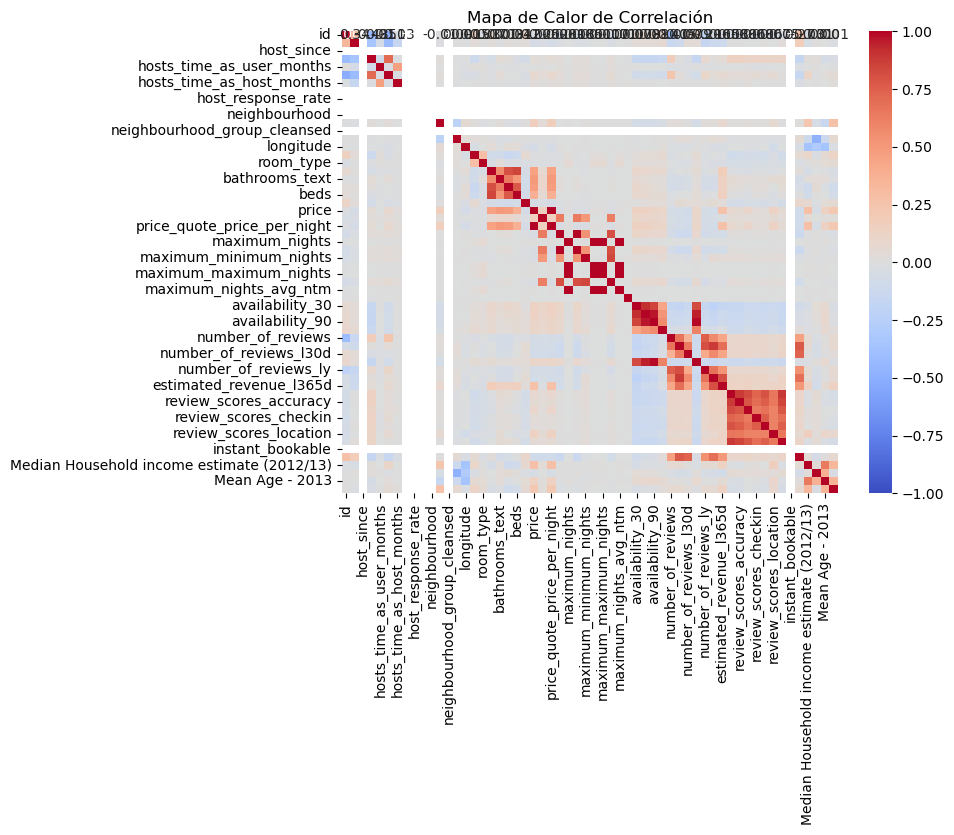

In [210]:
matriz = df_codificada.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(matriz, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Mapa de Calor de Correlación")
plt.show()


In [211]:
print(df_codificada.isnull().sum())

id                                                0
host_profile_id                                   0
host_since                                    39711
hosts_time_as_user_years                          0
hosts_time_as_user_months                         0
hosts_time_as_host_years                          0
hosts_time_as_host_months                         0
host_response_time                            39711
host_response_rate                            39711
host_acceptance_rate                          39711
neighbourhood                                 39711
neighbourhood_cleansed                            0
neighbourhood_group_cleansed                  39711
latitude                                          0
longitude                                         0
property_type                                     0
room_type                                         0
accommodates                                      0
bathrooms_text                                    0
bedrooms    

A continuación, se ha eliminado todas las filas las cuales no tenian valor 'beds', 'bedrooms' o 'bathrooms'
 ya que se consideran filas no validas ya que no tienen cama. El resto de valores, se considera que no es relevante que haya valores nulos.

In [212]:
df_codificada = df_codificada.dropna(subset=['beds', 'bedrooms'])

In [213]:
print(df_codificada.isnull().sum())

id                                                0
host_profile_id                                   0
host_since                                    38873
hosts_time_as_user_years                          0
hosts_time_as_user_months                         0
hosts_time_as_host_years                          0
hosts_time_as_host_months                         0
host_response_time                            38873
host_response_rate                            38873
host_acceptance_rate                          38873
neighbourhood                                 38873
neighbourhood_cleansed                            0
neighbourhood_group_cleansed                  38873
latitude                                          0
longitude                                         0
property_type                                     0
room_type                                         0
accommodates                                      0
bathrooms_text                                    0
bedrooms    

A continuación se han hecho unos gráficos de cajas para buscar posibles 'outliers'

In [214]:
X = df_codificada.drop(columns=['price'])
y = df_codificada['price']

In [215]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
modelo = HistGradientBoostingRegressor(random_state=42)
modelo.fit(X_train, y_train)

y_pred= modelo.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Evaluación del Modelo ---")
print(f"Error Absoluto Medio (MAE): {mae:.2f}")
print(f"Error Cuadrático Medio (MSE): {mse:.2f}")
print(f"Coeficiente de Determinación (R²): {r2:.2f}")

--- Evaluación del Modelo ---
Error Absoluto Medio (MAE): 0.96
Error Cuadrático Medio (MSE): 6.25
Coeficiente de Determinación (R²): 1.00


In [ ]:
df2= df_codificada.dropna(axis=1, how='any')

In [ ]:
X2 = df2.drop(columns=['price'])
y2 = df2['price']

In [ ]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size=0.2, random_state=42)

In [ ]:
modelo2 = RandomForestRegressor(n_estimators=250, random_state=42)
modelo2.fit(X_train2, y_train2)
y_pred2 = modelo2.predict(X_test2)

In [ ]:
mae2 = mean_absolute_error(y_test2, y_pred2)
mse2 = mean_squared_error(y_test2, y_pred2)
r22 = r2_score(y_test2, y_pred2)

print(f"Error Absoluto Medio (MAE): {mae2:.2f}")
print(f"Error Cuadrático Medio (MSE): {mse2:.2f}")
print(f"Coeficiente de Determinación (R²): {r22:.2f}")

Error Absoluto Medio (MAE): 53.13
Error Cuadrático Medio (MSE): 7498.22
Coeficiente de Determinación (R²): 0.70


c:\Users\tela\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


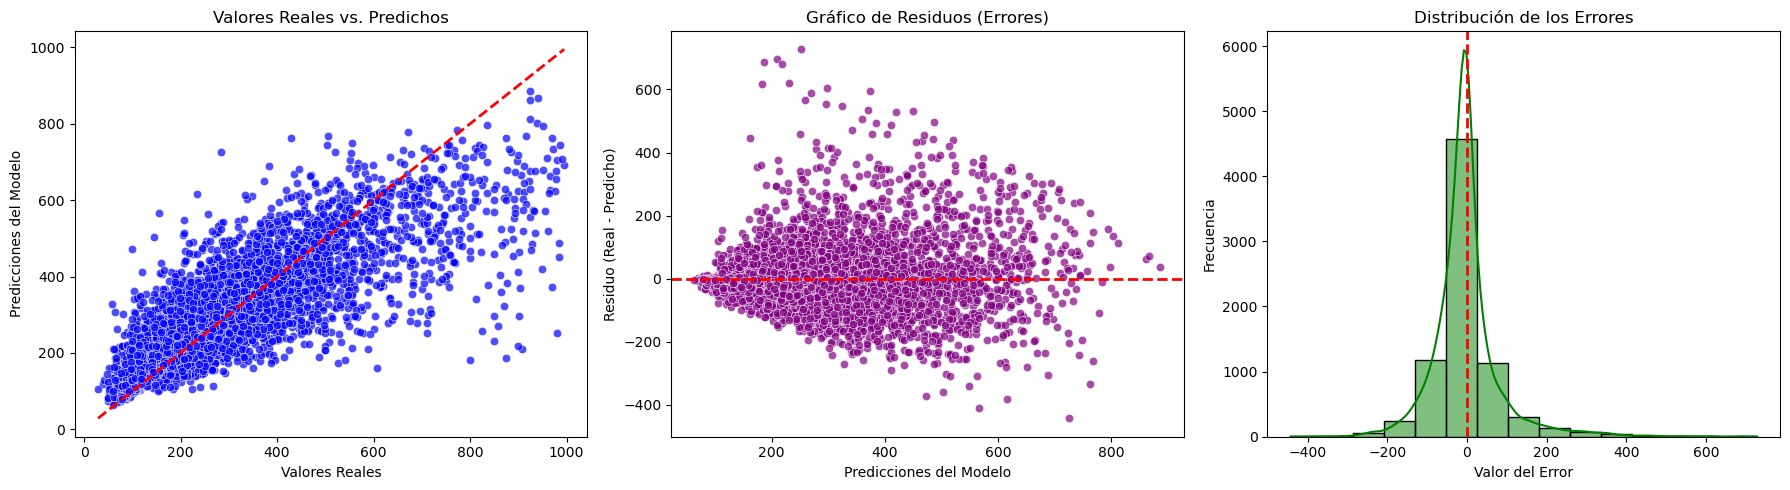

In [ ]:
y_test_arr = np.array(y_test2)
y_pred_arr = np.array(y_pred2)
residuos = y_test_arr - y_pred_arr

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=y_test_arr, y=y_pred_arr, ax=axes[0], color='blue', alpha=0.7)
max_val = max(y_test_arr.max(), y_pred_arr.max())
min_val = min(y_test_arr.min(), y_pred_arr.min())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2)
axes[0].set_title('Valores Reales vs. Predichos')
axes[0].set_xlabel('Valores Reales')
axes[0].set_ylabel('Predicciones del Modelo')


sns.scatterplot(x=y_pred_arr, y=residuos, ax=axes[1], color='purple', alpha=0.7)
axes[1].axhline(y=0, color='red', linestyle='--', lw=2)
axes[1].set_title('Gráfico de Residuos (Errores)')
axes[1].set_xlabel('Predicciones del Modelo')
axes[1].set_ylabel('Residuo (Real - Predicho)')

sns.histplot(residuos, kde=True, ax=axes[2], color='green', bins=15)
axes[2].axvline(x=0, color='red', linestyle='--', lw=2)
axes[2].set_title('Distribución de los Errores')
axes[2].set_xlabel('Valor del Error')
axes[2].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### Probando difentes codificaciones de las variables categóricas

In [216]:
columnas_a_eliminar = [
    'id',
    'host_profile_id',
    'price_quote_total_price',
    'price_quote_price_per_night',
    'price_quote_raw',
    'estimated_revenue_l365d',
]

df = df.drop(
    columns=columnas_a_eliminar,
    errors='ignore'
)

count    39711.000000
mean       266.179301
std        157.444517
min         20.000000
1%          72.210000
5%          99.000000
25%        159.570000
50%        223.500000
75%        325.000000
95%        593.000000
99%        843.900000
max        999.690000
Name: price, dtype: float64


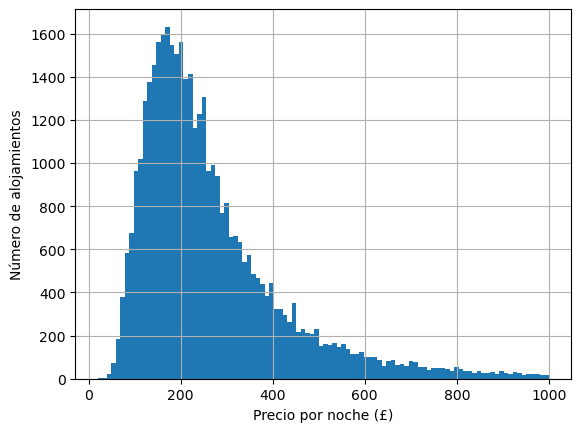

In [217]:
print(df['price'].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
))

df['price'].hist(bins=100)
plt.xlabel('Precio por noche (£)')
plt.ylabel('Número de alojamientos')
plt.show()

In [218]:
columnas_one_hot = ['room_type', 'property_type', 'has_availability']
columnas_label_encoder = ['neighbourhood_cleansed', 'bathrooms_text']



df = pd.get_dummies(df, columns=columnas_one_hot, dtype=int)
for c in columnas_label_encoder:
    le = LabelEncoder()
    df[c] = le.fit_transform(df[[c]])

c:\Users\tela\anaconda3\Lib\site-packages\sklearn\preprocessing\_label.py:116: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\tela\anaconda3\Lib\site-packages\sklearn\preprocessing\_label.py:116: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [219]:
df['bathrooms_text'].dtype

dtype('int32')

In [220]:

df['bathrooms_per_person'] = df['bathrooms_text'] / df['accommodates']

# --- DISTANCIA AL CENTRO ---
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371  # Radio de la Tierra en km
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    
    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlambda/2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R * c

lat_centro = 51.507222
lon_centro = -0.1275

df['distance_center_km'] = haversine_distance(
    df['latitude'], df['longitude'],
    lat_centro, lon_centro
)

# --- CONTEO DE AMENITIES ---
df['amenities_count'] = df['amenities'].str.count(',') + 1

# --- LUXURY SCORE ---
df['has_ac'] = df['amenities'].str.lower().str.contains('air conditioning').astype(int)
df['has_elevator'] = df['amenities'].str.lower().str.contains('elevator').astype(int)
df['has_pool'] = df['amenities'].str.lower().str.contains('pool').astype(int)
df['has_parking'] = df['amenities'].str.lower().str.contains('parking').astype(int)
df['has_jacuzzi'] = df['amenities'].str.lower().str.contains('jacuzzi').astype(int)

df.drop(columns=['amenities'], inplace=True)
print(df[['price', 'distance_center_km', 'bathrooms_per_person', 'amenities_count', 'has_ac']].head())

   price  distance_center_km  bathrooms_per_person  amenities_count  has_ac
0  267.5            5.190862              0.400000               44       1
2  137.5            3.546069              1.000000               25       1
3  228.0            4.732903              2.500000               71       0
5  290.0           11.010960              1.000000               47       0
6  517.5            1.883332              1.166667               41       1


In [229]:
X = df.drop(columns=['price'])
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = xgb.XGBRegressor(n_estimators=200, max_depth= 6, 
                          learning_rate=0.1,random_state=42)
modelo.fit(X_train, y_train)

y_pred= modelo.predict(X_test)

accuracy = modelo.score(X_test, y_test)
print(f"Precisión del modelo: {accuracy:.2f}")

Precisión del modelo: 0.67


In [222]:
df2= df.dropna(axis=1, how='any')
X2 = df2.drop(columns=['price'])
y2 = df2['price']
X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size=0.2, random_state=42)

Error Absoluto Medio (MAE): 63.07
Error Cuadrático Medio (MSE): 8936.09
Coeficiente de Determinación (R²): 0.63


c:\Users\tela\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


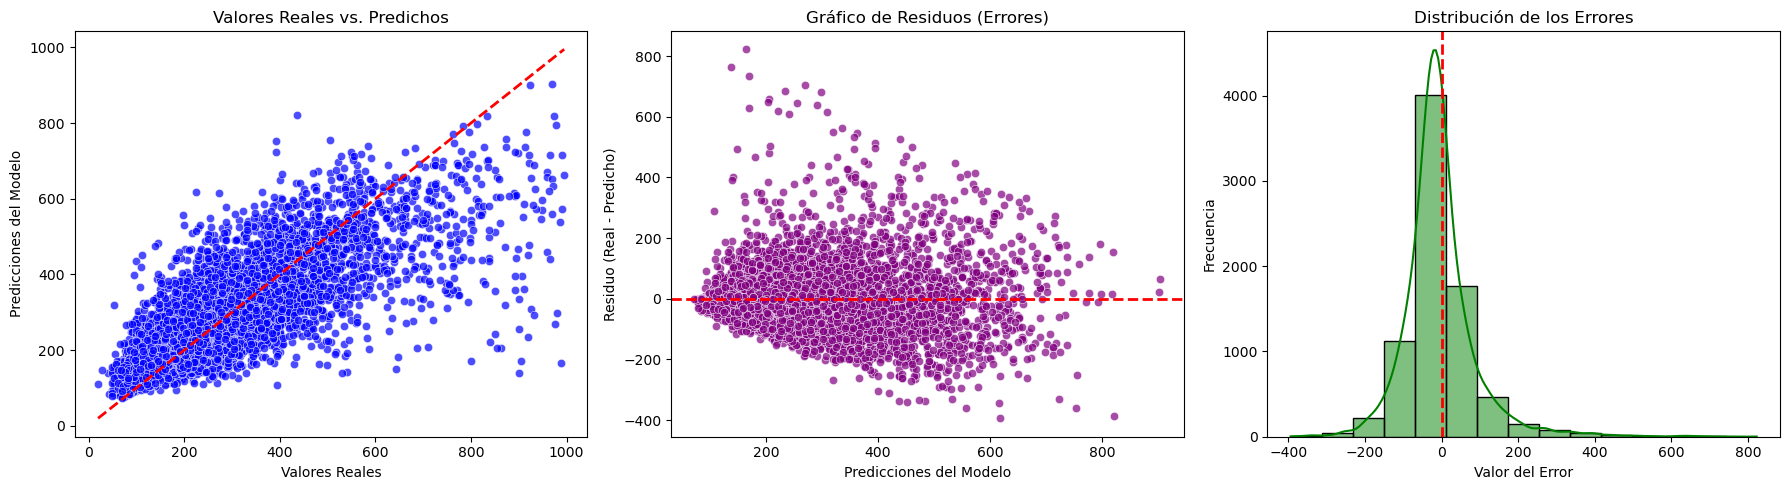

In [223]:
modelo2 = RandomForestRegressor(n_estimators=250, random_state=42)
modelo2.fit(X_train2, y_train2)
y_pred2 = modelo2.predict(X_test2)

mae2 = mean_absolute_error(y_test2, y_pred2)
mse2 = mean_squared_error(y_test2, y_pred2)
r22 = r2_score(y_test2, y_pred2)

print(f"Error Absoluto Medio (MAE): {mae2:.2f}")
print(f"Error Cuadrático Medio (MSE): {mse2:.2f}")
print(f"Coeficiente de Determinación (R²): {r22:.2f}")

y_test_arr = np.array(y_test2)
y_pred_arr = np.array(y_pred2)
residuos = y_test_arr - y_pred_arr

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=y_test_arr, y=y_pred_arr, ax=axes[0], color='blue', alpha=0.7)
max_val = max(y_test_arr.max(), y_pred_arr.max())
min_val = min(y_test_arr.min(), y_pred_arr.min())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2)
axes[0].set_title('Valores Reales vs. Predichos')
axes[0].set_xlabel('Valores Reales')
axes[0].set_ylabel('Predicciones del Modelo')


sns.scatterplot(x=y_pred_arr, y=residuos, ax=axes[1], color='purple', alpha=0.7)
axes[1].axhline(y=0, color='red', linestyle='--', lw=2)
axes[1].set_title('Gráfico de Residuos (Errores)')
axes[1].set_xlabel('Predicciones del Modelo')
axes[1].set_ylabel('Residuo (Real - Predicho)')

sns.histplot(residuos, kde=True, ax=axes[2], color='green', bins=15)
axes[2].axvline(x=0, color='red', linestyle='--', lw=2)
axes[2].set_title('Distribución de los Errores')
axes[2].set_xlabel('Valor del Error')
axes[2].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()